# 05 – Robustness checks

1. **Rolling-origin evaluation:** does the result hold in other test years, not only 2024/25?
2. **Feature-group ablation:** how much accuracy does each group of features add?

Both use the **14 core leagues** and the same leak-free rules as the main study.

In [1]:
import sys, warnings, json, time
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.config import RESULTS, SEED, set_seed, savefig, apply_plot_style, PALETTE, TEXT_SECONDARY, GRID
from src.features import FEATURES, FEATURE_INFO
from src.data import load_dataset, main_and_extra
from src.metrics import evaluate_frame, table, base_rates, WITHIN
from src.analysis import cluster_bootstrap_means, ci, verdict
from src.robustness import LGB_FIXED, GROUPS, group_features, fold, fit_lgb, predict_log
from src import models as M
from src.baselines import simple_baselines
BEST_INFO = json.load(open(RESULTS / "best_simple_baseline.json"))
BEST, AGE_STAT = BEST_INFO["best_simple_baseline"], BEST_INFO["age_curve_statistic"]

import numpy as np, pandas as pd, matplotlib.pyplot as plt

set_seed(SEED)
apply_plot_style()
pd.set_option("display.width", 170, "display.max_columns", 30)
main, _ = main_and_extra(load_dataset())
print(f"core rows: {len(main):,}")

core rows: 136,653


## 1. Rolling-origin evaluation (6 test years)

Each fold repeats the main design, shifted back in time one year at a time:

| fold | train (valuation date t) | validation | test |
|---|---|---|---|
| 2019/20 | Jul 2014 – Jun 2018 | Jul 2018 – Jun 2019 | Jul 2019 – Jun 2020 |
| … | … | … | … |
| 2024/25 (= main study) | Jul 2014 – Jun 2023 | Jul 2023 – Jun 2024 | from Jul 2024 |

The same rules apply in every fold:
- Training targets must be dated before the test year.
- Tuning uses only training rows whose target is dated before the validation year (embargo).
- The final fit uses all training rows.

**Models**
- **Naive** (no change).
- **Ridge:** alpha chosen on each fold's own validation year.
- **LightGBM** with **fixed settings chosen in advance** (the untuned settings of notebook 03, A3). Only the number of trees is chosen per fold, by early stopping on that fold's validation year.
  - We do *not* reuse the tuned settings from notebook 03. They were chosen on 2023/24 data, which lies *after* the earlier test years.
  - For the same reason, the 2024/25 LightGBM numbers here differ slightly from the tuned model in notebook 03.

**Simple baselines:** every fold also refits the simple baselines of notebook 03 on its own training rows. We report LightGBM against the **best simple baseline** chosen in notebook 03, (see `results/best_simple_baseline.json`). Using a baseline chosen on later data can only make the baseline look *better*, so this comparison is conservative for LightGBM.

**Note:** the 2019/20 test year includes the COVID-19 period. Transfermarkt cut many values in spring 2020, which makes it a hard year for every model.

In [2]:
YEARS = [2019, 2020, 2021, 2022, 2023, 2024]
folds = {y: fold(main, y, open_end=(y == YEARS[-1])) for y in YEARS}
rows = []
for y, f in folds.items():
    br = base_rates(f["test"])
    rows.append({"test year": f"{y}/{str(y + 1)[2:]}", "train rows": len(f["train"]), "tuning rows": len(f["tune"]),
                 "val rows": len(f["val"]), "test rows": len(f["test"]), "test players": f["test"].player_id.nunique(),
                 "train t to": f["train"].t.max().date(), "latest train target": f["train"].target_date.max().date(),
                 "test rose %": round(br["rose_%"], 1), "test fell %": round(br["fell_%"], 1)})
    assert f["train"].target_date.max() < f["test"].t.min()          # no training target in the test year
    assert f["tune"].target_date.max() < f["val"].t.min()           # embargo for tuning
fold_info = pd.DataFrame(rows).set_index("test year")
fold_info.to_csv(RESULTS / "table24_rolling_folds.csv")
fold_info

,train rows,tuning rows,val rows,test rows,test players,train t to,latest train target,test rose %,test fell %
test year,,,,,,,,,
2019/20,48312,36610,11176,11868,6453,2018-06-30,2019-06-30,34.9,55.5
2020/21,58580,48796,11868,15286,7362,2019-06-29,2020-06-30,33.5,52.4
2021/22,71442,58604,15286,13355,6853,2020-06-30,2021-06-30,32.2,53.4
2022/23,86687,72670,13355,12691,6339,2021-06-30,2022-06-30,35.7,50.6
2023/24,99933,86783,12691,11711,5450,2022-06-30,2023-06-30,36.8,49.4
2024/25,112775,99976,11711,12167,6292,2023-06-30,2024-06-30,35.4,51.5


In [3]:
quiet = lambda *a, **k: None
roll_rows, boot_rows, roll_preds = {}, [], []
for y, f in folds.items():
    t0 = time.time()
    label = f"{y}/{str(y + 1)[2:]}"
    te = f["test"]
    ridge, ridge_p, _, _ = M.tune_and_fit(M.Ridge_, f["tune"], f["val"], f["train"], log=quiet)
    lgbm, n_trees = fit_lgb(LGB_FIXED, FEATURES, f["tune"], f["val"], f["train"])
    P = {"Naive": te["log_value"].to_numpy(),
         "Ridge": te["log_value"].to_numpy() + ridge.predict(te[FEATURES]),
         "LightGBM": predict_log(lgbm, FEATURES, te)}
    for sname, sb in simple_baselines(AGE_STAT).items():
        if sname != "Naive (no change)":
            P[sname] = te["log_value"].to_numpy() + sb.fit(f["train"]).predict(te)
    for name, p in P.items():
        roll_rows[(label, name)] = evaluate_frame(te, p)
    err = pd.DataFrame({k: np.abs(p - te["y"].to_numpy()) for k, p in P.items()})
    b = cluster_bootstrap_means(te.player_id, err)
    for j, name in enumerate(["Ridge", "LightGBM"]):
        s = 100 * (1 - b[:, j + 1] / b[:, 0])
        boot_rows.append({"test year": label, "model": name, "skill_lo": ci(s)[0], "skill_hi": ci(s)[1]})
    d = b[:, 2] - b[:, 1]
    lo, hi = ci(d)
    boot_rows.append({"test year": label, "model": "LightGBM − Ridge (MAE)", "skill_lo": lo, "skill_hi": hi,
                      "verdict": verdict(lo, hi, "LightGBM", "Ridge")})
    keys = list(P)
    jb, jl = keys.index(BEST), keys.index("LightGBM")
    s = 100 * (1 - b[:, jb] / b[:, 0])
    boot_rows.append({"test year": label, "model": BEST, "skill_lo": ci(s)[0], "skill_hi": ci(s)[1]})
    s = 100 * (1 - b[:, jl] / b[:, jb])
    lo, hi = ci(b[:, jl] - b[:, jb])
    boot_rows.append({"test year": label, "model": "LightGBM − best simple (MAE)", "skill_lo": lo, "skill_hi": hi,
                      "verdict": verdict(lo, hi, "LightGBM", BEST),
                      "skill_vs_best_lo": ci(s)[0], "skill_vs_best_hi": ci(s)[1]})
    roll_preds.append(te[["player_id", "t", "y", "log_value"]].assign(test_year=label, **{f"pred_{k}": v for k, v in P.items()}))
    print(f"{label}: ridge alpha={ridge_p['alpha']}, LightGBM trees={n_trees} ({time.time() - t0:.0f}s)")

roll = table(roll_rows)
roll.index.names = ["test year", "model"]
naive = roll.xs("Naive", level="model")["MAE_change"]
roll["skill_vs_naive_%"] = [round(100 * (1 - r.MAE_change / naive[yl]), 1) for (yl, _), r in roll.iterrows()]
bdf = pd.DataFrame(boot_rows)
ci_map = {(r["test year"], r["model"]): f"[{r.skill_lo:.1f}, {r.skill_hi:.1f}]" for _, r in bdf.iterrows() if "−" not in r["model"]}
roll["skill 95% CI"] = [ci_map.get(i, "") for i in roll.index]
roll.to_csv(RESULTS / "table25_rolling_results.csv")
pd.concat(roll_preds, ignore_index=True).to_parquet(ROOT / "data" / "processed" / "predictions_rolling.parquet", index=False)
roll[["n", "MAE_change", "R2_change", "Spearman_change", "top10_rise_prec_%", "top10_fall_prec_%",
      "MdAPE_%", "within_20%", "skill_vs_naive_%", "skill 95% CI"]]

2019/20: ridge alpha=10000, LightGBM trees=33 (5s)


2020/21: ridge alpha=1, LightGBM trees=31 (5s)


2021/22: ridge alpha=1, LightGBM trees=176 (9s)


2022/23: ridge alpha=1, LightGBM trees=175 (10s)


2023/24: ridge alpha=100, LightGBM trees=106 (9s)


2024/25: ridge alpha=1000, LightGBM trees=155 (11s)


n  MAE_change  R2_change  Spearman_change  top10_rise_prec_%  top10_fall_prec_%  MdAPE_%  within_20%  skill_vs_naive_%  \
test year model                                                                                                                                                
2019/20   Naive                   11868      0.4433    -0.0053              NaN                NaN                NaN    33.33       32.45               0.0   
          Ridge                   11868      0.4005     0.2537           0.5313              69.76              86.02    33.58       32.36               9.7   
          LightGBM                11868      0.3923     0.2616           0.4965              71.44              84.25    31.33       34.24              11.5   
          Age-value curve         11868      0.4068     0.1928           0.4376              61.75              86.86    32.85       32.83               8.2   
          Age-value-league curve  11868      0.4165     0.1654           0.4152              62.68              78.52    33.18       31.90               6.0   
          Momentum                11868      0.7880    -2.6295           0.1796              58.47              64.20    50.00       19.30             -77.8   
          Momentum (damped)       11868      0.5246    -0.4541           0.1795              58.47              64.20    38.55       27.80             -18.3   
2020/21   Naive                   15286      0.4518    -0.0080              NaN                NaN                NaN    33.33       34.42               0.0   
          Ridge                   15286      0.3976     0.2939           0.5412              70.70              86.66    31.36       33.63              12.0   
          LightGBM                15286      0.3913     0.3011           0.5459              73.19              89.08    30.59       34.97              13.4   
          Age-value curve         15286      0.4220     0.1862           0.4230              59.25              83.85    32.74       33.65               6.6   
          Age-value-league curve  15286      0.4235     0.1845           0.4209              59.45              79.66    33.17       32.71               6.3   
          Momentum                15286      0.7291    -2.1334           0.3457              58.93              71.94    50.00       24.37             -61.4   
          Momentum (damped)       15286      0.5069    -0.3151           0.3457              58.93              71.94    37.61       30.39             -12.2   
2021/22   Naive                   13355      0.4434    -0.0077              NaN                NaN                NaN    33.33       34.21               0.0   
          Ridge                   13355      0.3818     0.3057           0.5426              69.16              88.02    29.75       35.58              13.9   
          LightGBM                13355      0.3732     0.3321           0.5630              70.13              91.39    28.56       37.16              15.8   
          Age-value curve         13355      0.4084     0.1961           0.4317              58.38              86.60    31.63       34.37               7.9   
          Age-value-league curve  13355      0.4094     0.1962           0.4334              59.06              85.03    31.58       34.04               7.7   
          Momentum                13355      0.6273    -1.4929           0.3778              61.75              72.98    41.30       27.79             -41.5   
          Momentum (damped)       13355      0.4590    -0.1267           0.3778              61.83              72.98    33.71       32.77              -3.5   
2022/23   Naive                   12691      0.4665    -0.0004              NaN                NaN                NaN    33.33       33.85               0.0   
          Ridge                   12691      0.4064     0.3062           0.5389              68.27              87.09    30.74       34.97              12.9   
          LightGBM                1269

### Is LightGBM better than Ridge, and than the best simple baseline, in every year?

The paired player-level bootstrap gives a 95% CI for each MAE difference. A negative value means LightGBM is better.

In [4]:
pair = bdf[bdf.model == "LightGBM − Ridge (MAE)"].copy()
pair["MAE(LightGBM) − MAE(Ridge)"] = [roll.loc[(y, "LightGBM"), "MAE_change"] - roll.loc[(y, "Ridge"), "MAE_change"]
                                      for y in pair["test year"]]
pair = pair.rename(columns={"skill_lo": "95% CI low", "skill_hi": "95% CI high"})[
    ["test year", "MAE(LightGBM) − MAE(Ridge)", "95% CI low", "95% CI high", "verdict"]].round(4)
pair.to_csv(RESULTS / "table25b_rolling_lightgbm_vs_ridge.csv", index=False)
best = bdf[bdf.model == "LightGBM − best simple (MAE)"].copy()
best["MAE(LightGBM) − MAE(best simple)"] = [roll.loc[(y, "LightGBM"), "MAE_change"] - roll.loc[(y, BEST), "MAE_change"]
                                            for y in best["test year"]]
best["skill vs best simple %"] = [round(100 * (1 - roll.loc[(y, "LightGBM"), "MAE_change"] / roll.loc[(y, BEST), "MAE_change"]), 1)
                                  for y in best["test year"]]
best["skill 95% CI"] = [f"[{a:.1f}, {b_:.1f}]" for a, b_ in zip(best.skill_vs_best_lo, best.skill_vs_best_hi)]
best = best.rename(columns={"skill_lo": "95% CI low", "skill_hi": "95% CI high"})[
    ["test year", "MAE(LightGBM) − MAE(best simple)", "95% CI low", "95% CI high", "verdict",
     "skill vs best simple %", "skill 95% CI"]].round(4)
best.to_csv(RESULTS / "table25c_rolling_lightgbm_vs_best_simple.csv", index=False)
print(f"Best simple baseline: {BEST}")
display(best)
summary = roll.reset_index().groupby("model", sort=False).agg(
    mean_skill=("skill_vs_naive_%", "mean"), min_skill=("skill_vs_naive_%", "min"), max_skill=("skill_vs_naive_%", "max"),
    mean_within20=("within_20%", "mean"), mean_spearman=("Spearman_change", "mean")).round(2)
display(pair)
summary

Best simple baseline: Age-value curve


,test year,MAE(LightGBM) − MAE(best simple),95% CI low,95% CI high,verdict,skill vs best simple %,skill 95% CI
4,2019/20,-0.0145,-0.0179,-0.0107,LightGBM better,3.6,"[2.6, 4.4]"
9,2020/21,-0.0307,-0.0342,-0.0274,LightGBM better,7.3,"[6.5, 8.0]"
14,2021/22,-0.0352,-0.0399,-0.0305,LightGBM better,8.6,"[7.5, 9.7]"
19,2022/23,-0.0210,-0.0258,-0.0164,LightGBM better,5.0,"[4.0, 6.0]"
24,2023/24,-0.0171,-0.0220,-0.0124,LightGBM better,4.2,"[3.0, 5.3]"
29,2024/25,-0.0245,-0.0292,-0.0201,LightGBM better,5.8,"[4.8, 6.8]"


,test year,MAE(LightGBM) − MAE(Ridge),95% CI low,95% CI high,verdict
2,2019/20,-0.0082,-0.0110,-0.0055,LightGBM better
7,2020/21,-0.0063,-0.0087,-0.0037,LightGBM better
12,2021/22,-0.0086,-0.0117,-0.0058,LightGBM better
17,2022/23,-0.0062,-0.0093,-0.0032,LightGBM better
22,2023/24,-0.0071,-0.0105,-0.0041,LightGBM better
27,2024/25,-0.0094,-0.0122,-0.0064,LightGBM better


,mean_skill,min_skill,max_skill,mean_within20,mean_spearman
model,,,,,
Naive,0.00,0.0,0.0,33.51,NaN
Ridge,12.80,9.7,15.1,34.44,0.55
LightGBM,14.45,11.5,17.1,35.90,0.55
Age-value curve,9.23,6.6,12.0,34.48,0.46
Age-value-league curve,8.63,6.0,11.8,33.80,0.46
Momentum,-48.67,-77.8,-33.3,26.26,0.35
Momentum (damped),-6.62,-18.3,-0.2,31.50,0.35


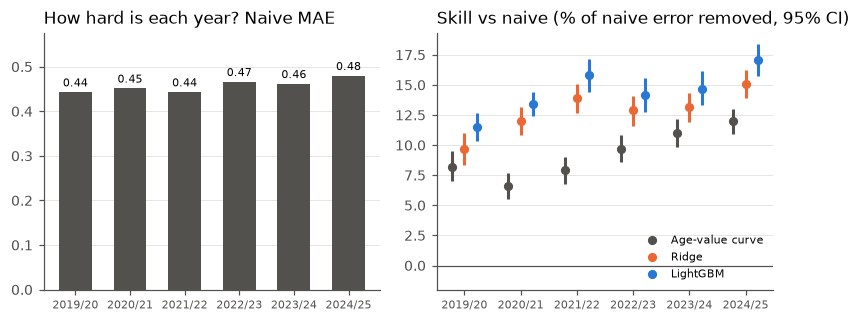

In [5]:
labels = [f"{y}/{str(y + 1)[2:]}" for y in YEARS]
x = np.arange(len(labels))
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
nv = roll.xs("Naive", level="model")["MAE_change"].loc[labels]
axes[0].bar(x, nv, color=TEXT_SECONDARY, width=0.6)
axes[0].bar_label(axes[0].containers[0], fmt="%.2f", fontsize=7, padding=2)
axes[0].set_xticks(x, labels, fontsize=7)
axes[0].set_title("How hard is each year? Naive MAE", loc="left")
axes[0].set_ylim(0, nv.max() * 1.2)
for k, (name, color, off) in enumerate([(BEST, TEXT_SECONDARY, -0.22), ("Ridge", PALETTE[1], 0.0), ("LightGBM", PALETTE[0], 0.22)]):
    s = roll.xs(name, level="model").loc[labels, "skill_vs_naive_%"]
    b = bdf[bdf.model == name].set_index("test year").loc[labels]
    axes[1].vlines(x + off, b.skill_lo, b.skill_hi, color=color, linewidth=2)
    axes[1].plot(x + off, s, "o", color=color, markersize=5, label=name)
axes[1].axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
axes[1].set_xticks(x, labels, fontsize=7)
axes[1].set_title("Skill vs naive (% of naive error removed, 95% CI)", loc="left")
axes[1].legend(loc="lower right", fontsize=7)
axes[1].set_ylim(min(0, bdf[bdf.model.isin([BEST, "Ridge", "LightGBM"])].skill_lo.min()) - 2, None)
fig.tight_layout()
savefig(fig, "fig13_rolling_origin")
plt.show()

## 2. Feature-group ablation (main split, test year 2024/25)

- **Model:** LightGBM with the **tuned settings** from notebook 03 (`results/best_params.json`).
- **Variants:** we retrain it
  - without each feature group in turn;
  - on value history alone;
  - on value history + age.
- **Protocol** (same as notebook 03): early stopping on validation picks the number of trees for each variant, then the model is refit on all training rows and scored once on the test set.
- **Paired bootstrap:** for each variant, the player-level bootstrap gives a CI for MAE(variant) − MAE(full model). A positive value means the model is **worse** without that group, i.e. the group adds accuracy.

**Reading the results:** value information is not only in the "value history" group. `value_vs_club_mean` and `value_vs_league_median` (club/league group) also contain the player's current value. So dropping one group does not remove all value information.

In [6]:
best = json.load(open(RESULTS / "best_params.json"))["LightGBM"]
LGB_TUNED = {k: v for k, v in best.items() if k != "n_trees"} | {"learning_rate": 0.03, "subsample_freq": 1}
mf = fold(main, 2024, open_end=True)
variants = {"full model (50 features)": FEATURES}
for g in GROUPS:
    variants[f"without {g}"] = [f for f in FEATURES if FEATURE_INFO[f][0] != g]
variants["value history only"] = group_features("value history")
variants["value history + age"] = group_features("value history") + ["age"]

te = mf["test"]
abl_rows, preds = {}, {}
for name, feats in variants.items():
    t0 = time.time()
    model, n = fit_lgb(LGB_TUNED, feats, mf["tune"], mf["val"], mf["train"])
    preds[name] = predict_log(model, feats, te)
    abl_rows[name] = evaluate_frame(te, preds[name]) | {"features": len(feats), "trees": n}
    print(f"{name:32s} {len(feats):2d} features, {n:4d} trees, MAE {abl_rows[name]['MAE_change']:.4f} ({time.time() - t0:.0f}s)")
abl_rows["naive (no change)"] = evaluate_frame(te, te["log_value"].to_numpy()) | {"features": 0, "trees": 0}
preds["naive (no change)"] = te["log_value"].to_numpy()

full model (50 features)         50 features,  596 trees, MAE 0.3940 (11s)


without player                   44 features,  530 trees, MAE 0.3992 (10s)


without value history            39 features,  707 trees, MAE 0.4029 (12s)


without performance              35 features,  347 trees, MAE 0.4004 (7s)


without transfers                46 features,  855 trees, MAE 0.3944 (15s)


without club/league              36 features,  552 trees, MAE 0.3979 (9s)


value history only               11 features,  111 trees, MAE 0.4099 (3s)


value history + age              12 features,  271 trees, MAE 0.4045 (5s)


In [7]:
names = list(preds)
err = pd.DataFrame({k: np.abs(p - te["y"].to_numpy()) for k, p in preds.items()})
b = cluster_bootstrap_means(te.player_id, err)
full_j = names.index("full model (50 features)")
abl = table({k: {kk: vv for kk, vv in v.items() if kk not in ("features", "trees")} for k, v in abl_rows.items()},
            naive_key="naive (no change)")
abl.insert(0, "features", [abl_rows[k]["features"] for k in abl.index])
abl.insert(1, "trees", [abl_rows[k]["trees"] for k in abl.index])
d_rows = []
for k in abl.index:
    j = names.index(k)
    d = b[:, j] - b[:, full_j]
    lo, hi = ci(d)
    d_rows.append({"ΔMAE vs full": err[k].mean() - err.iloc[:, full_j].mean(), "Δ 95% CI low": lo, "Δ 95% CI high": hi,
                   "verdict": "—" if j == full_j else ("no clear difference" if lo <= 0 <= hi
                                                       else ("worse than full" if lo > 0 else "better than full"))})
abl = pd.concat([abl, pd.DataFrame(d_rows, index=abl.index).round(4)], axis=1)
abl.to_csv(RESULTS / "table26_feature_group_ablation.csv")
abl[["features", "trees", "MAE_change", "ΔMAE vs full", "Δ 95% CI low", "Δ 95% CI high", "verdict",
     "Spearman_change", "within_20%", "skill_vs_naive_%"]]

,features,trees,MAE_change,ΔMAE vs full,Δ 95% CI low,Δ 95% CI high,verdict,Spearman_change,within_20%,skill_vs_naive_%
full model (50 features),50,596,0.3940,0.0000,0.0000,0.0000,—,0.5849,37.80,17.9
without player,44,530,0.3992,0.0052,0.0039,0.0066,worse than full,0.5692,37.41,16.8
without value history,39,707,0.4029,0.0089,0.0070,0.0109,worse than full,0.5596,36.62,16.1
without performance,35,347,0.4004,0.0064,0.0051,0.0077,worse than full,0.5695,37.47,16.6
without transfers,46,855,0.3944,0.0004,-0.0012,0.0020,no clear difference,0.5818,38.72,17.8
without club/league,36,552,0.3979,0.0039,0.0021,0.0056,worse than full,0.5791,37.70,17.1
value history only,11,111,0.4099,0.0158,0.0130,0.0187,worse than full,0.5501,37.61,14.6
value history + age,12,271,0.4045,0.0105,0.0077,0.0130,worse than full,0.5632,37.69,15.7
naive (no change),0,0,0.4800,0.0860,0.0797,0.0921,worse than full,NaN,32.20,0.0


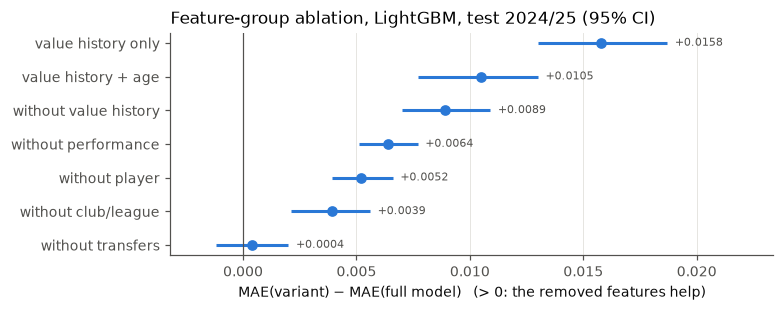

In [8]:
plot = abl.drop(index=["full model (50 features)", "naive (no change)"])
plot = plot.sort_values("ΔMAE vs full")
fig, ax = plt.subplots(figsize=(7.2, 2.9))
y = np.arange(len(plot))
ax.hlines(y, plot["Δ 95% CI low"], plot["Δ 95% CI high"], color=PALETTE[0], linewidth=2)
ax.plot(plot["ΔMAE vs full"], y, "o", color=PALETTE[0], markersize=6)
for yi, (_, r) in zip(y, plot.iterrows()):
    ax.annotate(f"{r['ΔMAE vs full']:+.4f}", (r["Δ 95% CI high"], yi), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=7, color=TEXT_SECONDARY)
ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_yticks(y, plot.index)
ax.set_xlabel("MAE(variant) − MAE(full model)   (> 0: the removed features help)")
ax.set_title("Feature-group ablation, LightGBM, test 2024/25 (95% CI)", loc="left")
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlim(min(0, plot["Δ 95% CI low"].min()) - 0.002, plot["Δ 95% CI high"].max() * 1.25)
fig.tight_layout()
savefig(fig, "fig14_feature_group_ablation")
plt.show()

## 2b. Club transfer spending (comparison with McHale & Holmes, 2023)

McHale & Holmes found that the **buying club's transfer spending** was the strongest predictor of transfer fees. Our setting differs:
- We forecast the **market value 12 months ahead**, not a transfer fee.
- The closest equivalent is the spending of the player's **club at *t***, over the 3 years before *t*.

Two extra variants (same LightGBM, settings and protocol as section 2):
- **without club finance:** drops all three club transfer-money features (`club_log_spend_3y`, `club_log_income_3y`, `club_net_spend_3y_m`);
- **without club spending only:** drops just `club_log_spend_3y`, fees paid by the club.

For context, the table also gives each feature's SHAP rank from notebook 04.

In [9]:
FIN = ["club_log_spend_3y", "club_log_income_3y", "club_net_spend_3y_m"]
fin_variants = {"without club finance (3 features)": [f for f in FEATURES if f not in FIN],
                "without club spending only": [f for f in FEATURES if f != "club_log_spend_3y"]}
for name, feats in fin_variants.items():
    t0 = time.time()
    model, n = fit_lgb(LGB_TUNED, feats, mf["tune"], mf["val"], mf["train"])
    preds[name] = predict_log(model, feats, te)
    abl_rows[name] = evaluate_frame(te, preds[name]) | {"features": len(feats), "trees": n}
    print(f"{name:36s} {len(feats):2d} features, {n:4d} trees, MAE {abl_rows[name]['MAE_change']:.4f} ({time.time() - t0:.0f}s)")

cmp_names = ["full model (50 features)", "without club finance (3 features)", "without club spending only",
             "without club/league"]
err2 = pd.DataFrame({k: np.abs(preds[k] - te["y"].to_numpy()) for k in cmp_names})
b2 = cluster_bootstrap_means(te.player_id, err2)
rows = []
for j, k in enumerate(cmp_names):
    d = b2[:, j] - b2[:, 0]
    lo, hi = ci(d)
    r = abl_rows[k]
    rows.append({"variant": k, "features": r["features"], "trees": r["trees"], "MAE_change": r["MAE_change"],
                 "ΔMAE vs full": err2[k].mean() - err2.iloc[:, 0].mean(), "Δ 95% CI low": lo, "Δ 95% CI high": hi,
                 "verdict": "—" if j == 0 else ("no clear difference" if lo <= 0 <= hi
                                                else ("worse than full" if lo > 0 else "better than full")),
                 "Spearman_change": r["Spearman_change"], "within_20%": r["within_20%"]})
fin_abl = pd.DataFrame(rows).set_index("variant").round(4)
fin_abl.to_csv(RESULTS / "table26b_club_spending_ablation.csv")
display(fin_abl)

shap_rank = pd.read_csv(RESULTS / "table21_shap_importance.csv").set_index("feature")
display(shap_rank.loc[FIN, ["rank", "mean_abs_SHAP", "direction"]].assign(of=len(shap_rank)))

without club finance (3 features)    47 features,  540 trees, MAE 0.3946 (10s)


without club spending only           49 features,  542 trees, MAE 0.3943 (10s)


,features,trees,MAE_change,ΔMAE vs full,Δ 95% CI low,Δ 95% CI high,verdict,Spearman_change,within_20%
variant,,,,,,,,,
full model (50 features),50,596,0.3940,0.0000,0.0000,0.0000,—,0.5849,37.7990
without club finance (3 features),47,540,0.3946,0.0006,-0.0001,0.0012,no clear difference,0.5828,38.0455
without club spending only,49,542,0.3943,0.0003,-0.0004,0.0009,no clear difference,0.5833,38.2263
without club/league,36,552,0.3979,0.0039,0.0021,0.0056,worse than full,0.5791,37.7003


,rank,mean_abs_SHAP,direction,of
feature,,,,
club_log_spend_3y,36,0.0033,higher value → higher forecast (ρ=0.27),50
club_log_income_3y,34,0.0042,mixed / non-monotone (ρ=0.01),50
club_net_spend_3y_m,33,0.0050,higher value → lower forecast (ρ=-0.70),50


**Why might club spending add so little here?** One check is whether it overlaps with other club features the model already has. Below: Spearman correlations on the training rows.

In [10]:
other = ["club_log_total_value", "club_mean_log_value", "league_median_log_value", "club_gd_per_game_365"]
tr_rows = mf["train"]
overlap = tr_rows[FIN + other].corr(method="spearman").loc[FIN, other].round(2)
overlap.to_csv(RESULTS / "table26c_club_spending_overlap.csv")
print(f"training rows whose club paid no fee in the last 3 years: {100 * (tr_rows.club_log_spend_3y == 0).mean():.1f}%")
overlap

training rows whose club paid no fee in the last 3 years: 16.1%


,club_log_total_value,club_mean_log_value,league_median_log_value,club_gd_per_game_365
club_log_spend_3y,0.91,0.90,0.67,0.47
club_log_income_3y,0.79,0.76,0.50,0.44
club_net_spend_3y_m,0.20,0.21,0.29,0.04


## Summary
See the chat summary. Tables: `table24`–`table26c` in `results/`. Figures: `fig13`, `fig14`.